In [4]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import imdb

In [5]:
vocab_size = 10000

(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [6]:
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 25000
Testing samples: 25000


In [7]:
#CHECK FIRST REVIEW
print("First review:")
print(X_train[0])

First review:
[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 5952, 15, 256, 4, 2, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1334, 88, 12, 16, 283, 5, 16, 4472, 113, 103, 32, 15, 16, 5345, 19, 178, 32]


In [8]:
#CHECK FIRST REVIEW LABLE
print("First review label:", y_train[0])

First review label: 1


In [9]:
#CHECK LABLE DISTRBUTION
unique, counts = np.unique(y_train, return_counts=True)

for label, count in zip(unique, counts):
    print(f"Label {label}: {count}")

Label 0: 12500
Label 1: 12500


In [10]:
#GET WORD INDEX
word_index = imdb.get_word_index()

print("Vocabulary size:", len(word_index))
print("First 20 words:")
print(list(word_index.items())[:20])

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 1s 1us/step
Vocabulary size: 88584
First 20 words:
[('fawn', 34701), ('tsukino', 52006), ('nunnery', 52007), ('sonja', 16816), ('vani', 63951), ('woods', 1408), ('spiders', 16115), ('hanging', 2345), ('woody', 2289), ('trawling', 52008), ("hold's", 52009), ('comically', 11307), ('localized', 40830), ('disobeying', 30568), ("'royale", 52010), ("harpo's", 40831), ('canet', 52011), ('aileen', 19313), ('acurately', 52012), ("diplomat's", 52013)]


In [11]:
#DECODE A REVIEW
reverse_word_index = {
    value + 3: key
    for key, value in word_index.items()
}

reverse_word_index[0] = "<PAD>"
reverse_word_index[1] = "<START>"
reverse_word_index[2] = "<UNK>"
reverse_word_index[3] = "<UNUSED>"

decoded_review = " ".join(
    reverse_word_index.get(i, "?")
    for i in X_train[0]
)

print(decoded_review)

<START> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <UNK> is an amazing actor and now the same being director <UNK> father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for <UNK> and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also <UNK> to the two little boy's that played the <UNK> of norman and paul they were just brilliant children are often left out of the <UNK> list i think because the stars that play them all grown up are such a big profile for the whole film but these children are amazing and should be praised for wha

In [12]:
#CALCULATE REVIEW LENGTH
train_lengths = [len(review) for review in X_train]
test_lengths = [len(review) for review in X_test]

print("Minimum review length:", min(train_lengths))
print("Maximum review length:", max(train_lengths))
print("Average review length:", np.mean(train_lengths))

Minimum review length: 11
Maximum review length: 2494
Average review length: 238.71364


In [13]:
#REVIEW LENGTH STATISTICS
print("25th percentile:", np.percentile(train_lengths, 25))
print("50th percentile:", np.percentile(train_lengths, 50))
print("75th percentile:", np.percentile(train_lengths, 75))
print("90th percentile:", np.percentile(train_lengths, 90))
print("95th percentile:", np.percentile(train_lengths, 95))

25th percentile: 130.0
50th percentile: 178.0
75th percentile: 291.0
90th percentile: 467.0
95th percentile: 610.0


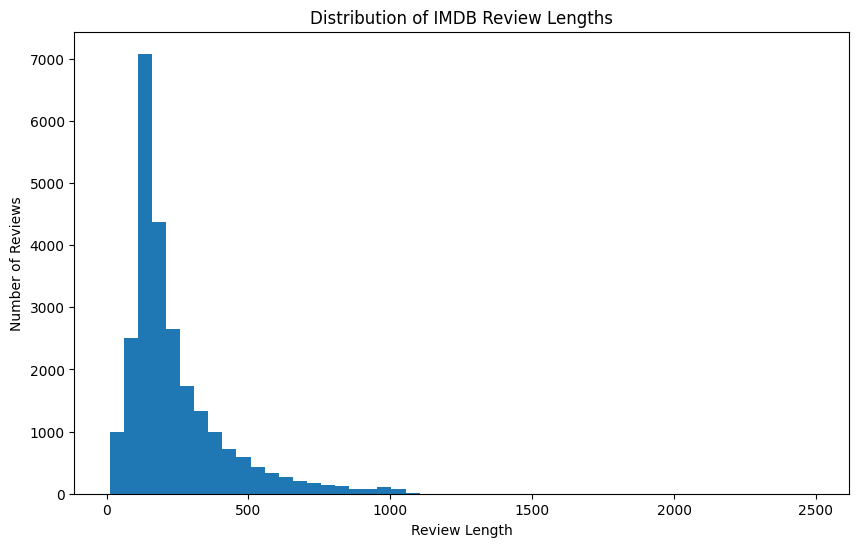

In [14]:
#REVIEW LENGTH DISTRIBUTION
plt.figure(figsize=(10, 6))

plt.hist(train_lengths, bins=50)

plt.title("Distribution of IMDB Review Lengths")
plt.xlabel("Review Length")
plt.ylabel("Number of Reviews")

plt.show()

In [15]:
print("IMDB DATASET SUMMARY")
print("Vocabulary size:", vocab_size)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Positive reviews:", np.sum(y_train == 1))
print("Negative reviews:", np.sum(y_train == 0))
print("Minimum review length:", min(train_lengths))
print("Maximum review length:", max(train_lengths))
print("Average review length:", round(np.mean(train_lengths), 2))

IMDB DATASET SUMMARY
Vocabulary size: 10000
Training samples: 25000
Testing samples: 25000
Positive reviews: 12500
Negative reviews: 12500
Minimum review length: 11
Maximum review length: 2494
Average review length: 238.71


In [16]:
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

In [17]:
#DEFINE MAX SEQUENCE LENGTH
maxlen = 500

print("Vocabulary size:", vocab_size)
print("Maximum sequence length:", maxlen)

Vocabulary size: 10000
Maximum sequence length: 500


In [18]:
#CREATING VALIDATION AND TRAINING SPLIT
X_train_raw, X_val_raw, y_train_final, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training samples:", len(X_train_raw))
print("Validation samples:", len(X_val_raw))

Training samples: 20000
Validation samples: 5000


In [19]:
#PAD AND TRANCUATE TRAINING DATA
X_train_final = pad_sequences(
    X_train_raw,
    maxlen=maxlen,
    padding="post",
    truncating="post"
)

In [20]:
#PAD AND TRUNCATE VALIDATION DATA
X_val = pad_sequences(
    X_val_raw,
    maxlen=maxlen,
    padding="post",
    truncating="post"
)

In [21]:
#PAD AND TRUNCATE TEST DATA
X_test_padded = pad_sequences(
    X_test,
    maxlen=maxlen,
    padding="post",
    truncating="post"
)

In [22]:
#CHECK SHAPES
print("Training data shape:", X_train_final.shape)
print("Validation data shape:", X_val.shape)
print("Test data shape:", X_test_padded.shape)

print("Training labels shape:", y_train_final.shape)
print("Validation labels shape:", y_val.shape)
print("Test labels shape:", y_test.shape)

Training data shape: (20000, 500)
Validation data shape: (5000, 500)
Test data shape: (25000, 500)
Training labels shape: (20000,)
Validation labels shape: (5000,)
Test labels shape: (25000,)


In [23]:
#SEE PADDING ON ACTUAL REVIEW
print("Original review:")
print(X_train_raw[0])

print("\nOriginal length:")
print(len(X_train_raw[0]))

print("\nPadded review:")
print(X_train_final[0])

print("\nPadded length:")
print(len(X_train_final[0]))

Original review:
[1, 806, 8, 135, 13, 28, 57, 326, 51, 363, 9, 399, 252, 202, 178, 102, 40, 1354, 778, 449, 34, 4, 96, 363, 13, 104, 36, 203, 1108, 4, 65, 347, 11, 4, 20, 1354, 21, 591, 92, 2836, 178, 51, 75, 62, 66, 181, 8, 67, 1354, 5, 1832, 295, 13, 66, 1800, 14, 1472, 88, 12, 317, 72, 1786, 18, 53, 13, 16, 267, 187, 8, 67, 54, 12, 16, 582, 46, 12, 16, 40, 6, 394, 7992, 975, 4, 2876, 121, 52, 4, 65, 347, 468, 1156, 5, 12, 69, 32, 4, 2, 7, 6, 87, 20, 472, 45, 24, 170, 8, 593, 18, 150, 8, 4, 1180, 907, 5, 32, 4, 156, 87, 292, 21, 13, 784, 25, 18, 399, 14, 8, 72, 25, 317, 72, 1786, 53]

Original length:
133

Padded review:
[   1  806    8  135   13   28   57  326   51  363    9  399  252  202
  178  102   40 1354  778  449   34    4   96  363   13  104   36  203
 1108    4   65  347   11    4   20 1354   21  591   92 2836  178   51
   75   62   66  181    8   67 1354    5 1832  295   13   66 1800   14
 1472   88   12  317   72 1786   18   53   13   16  267  187    8   67
   54   12   1

In [24]:
#CHECK UNKNOWN WORDS
print("Unknown token ID:", 2)
print("Unknown tokens in first review:", X_train_raw[0].count(2))

Unknown token ID: 2
Unknown tokens in first review: 1


In [25]:
# VERIFY LENGTH OF EVERY SEQUENCE EQUAL 500
print("Training sequence lengths:", np.unique([len(x) for x in X_train_final]))
print("Validation sequence lengths:", np.unique([len(x) for x in X_val]))
print("Test sequence lengths:", np.unique([len(x) for x in X_test_padded]))


Training sequence lengths: [500]
Validation sequence lengths: [500]
Test sequence lengths: [500]


In [26]:
#CALCULATE HOW MANY REVIEWS FIT IN MAXLEN
percentage_within_maxlen = np.mean(
    np.array(train_lengths) <= maxlen
) * 100

print(
    f"Percentage of training reviews with length <= {maxlen}: "
    f"{percentage_within_maxlen:.2f}%"
)

Percentage of training reviews with length <= 500: 91.57%


In [27]:
#VERIFY CLASS DISTRIBUTION AFTER SPLIT
print("Training Positive:", np.sum(y_train_final == 1))
print("Training Negative:", np.sum(y_train_final == 0))

print("Validation Positive:", np.sum(y_val == 1))
print("Validation Negative:", np.sum(y_val == 0))

Training Positive: 10000
Training Negative: 10000
Validation Positive: 2500
Validation Negative: 2500


In [28]:
#Import Required Libraries / Layers

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense

# Define Model Hyperparameters
vocab_size = 10000
maxlen = 500
embedding_dim = 128
lstm_units = 64
dense_units = 32
print("Vocabulary Size:", vocab_size)
print("Maximum Sequence Length:", maxlen)
print("Embedding Dimension:", embedding_dim)
print("LSTM Units:", lstm_units)
print("Dense Units:", dense_units)

# Build the LSTM Model
model_lstm = Sequential([
Input(shape=(maxlen,)),
Embedding(
input_dim=vocab_size,
output_dim=embedding_dim,
mask_zero=True ),

LSTM(lstm_units),
Dense(dense_units, activation="relu"),
Dense(1, activation="sigmoid")
])

model_lstm.summary()
print("Training data shape:", X_train_final.shape)
print("Validation data shape:", X_val.shape)
print("Test data shape:", X_test_padded.shape)

sample_input = X_train_final[:1]

print("Input shape:", sample_input.shape)

# Display the first 20 token IDs
print("First 20 token IDs:")
print(sample_input[0][:20])

#Test the Embedding Layer Separately

embedding_layer = model_lstm.layers[0]
sample_embedding = embedding_layer(sample_input)
print("Embedding output shape:", sample_embedding.shape)

# Inspect One Token's Embedding Vector
first_token_vector = sample_embedding[0, 0]

print("First token embedding vector:")
print(first_token_vector)

print("\nVector shape:")
print(first_token_vector.shape)

#Show the Complete Data Flow Using Shapes

batch_size_example = 64

print("Example input shape:")
print((batch_size_example, maxlen))

print("\nAfter Embedding:")
print((batch_size_example, maxlen, embedding_dim))

print("\nAfter LSTM:")
print((batch_size_example, lstm_units))

print("\nAfter Dense:")
print((batch_size_example, dense_units))

print("\nFinal Output:")
print((batch_size_example, 1))

Vocabulary Size: 10000
Maximum Sequence Length: 500
Embedding Dimension: 128
LSTM Units: 64
Dense Units: 32


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 500, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,331,521 (5.08 MB)

 Trainable params: 1,331,521 (5.08 MB)

 Non-trainable params: 0 (0.00 B)

Training data shape: (20000, 500)
Validation data shape: (5000, 500)
Test data shape: (25000, 500)
Input shape: (1, 500)
First 20 token IDs:
[   1  806    8  135   13   28   57  326   51  363    9  399  252  202
  178  102   40 1354  778  449]
Embedding output shape: (1, 500, 128)
First token embedding vector:
tf.Tensor(
[ 4.65321057e-02  3.00410129e-02 -3.12690362e-02  2.60636695e-02
  4.08351682e-02  2.19430216e-02 -2.97236573e-02  1.56365149e-02
  1.59925111e-02 -3.64403129e-02  1.12311468e-02 -1.02867000e-02
  4.77055646e-02  3.84739153e-02  8.90109688e-03  6.66469336e-03
  3.85038964e-02  7.97709078e-03  4.99087609e-02 -3.91693823e-02
 -2.96709184e-02 -3.07339784e-02 -1.79142132e-02 -2.28619464e-02
  7.98980147e-03 -4.54836749e-02 -3.75902280e-02  4.98284586e-02
  8.79729912e-03 -4.03464325e-02 -4.16580327e-02 -2.76055187e-03
 -3.13735157e-02 -3.82201560e-02 -1.50374398e-02  4.66830619e-02
  1.50425173e-02  3.44489105e-02  3.91903855e-02 -6.15597889e-03
 -3.97123694e-02 -1.9592583

Batch size: 64
Epochs: 10
Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 12s 27ms/step - accuracy: 0.7861 - loss: 0.4406 - val_accuracy: 0.8596 - val_loss: 0.3335
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - accuracy: 0.8878 - loss: 0.2818 - val_accuracy: 0.8734 - val_loss: 0.3150
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.9255 - loss: 0.1953 - val_accuracy: 0.8516 - val_loss: 0.3415
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 27ms/step - accuracy: 0.9341 - loss: 0.1700 - val_accuracy: 0.8660 - val_loss: 0.3515
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - accuracy: 0.9627 - loss: 0.1078 - val_accuracy: 0.8706 - val_loss: 0.4543
Epoch 6/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 24ms/step - accuracy: 0.9703 - loss: 0.0860 - val_accuracy: 0.8396 - val_loss: 0.4413
Epoch 7/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - accuracy: 0.9782 - loss: 0.0640 - val_accuracy: 0.8576 - val_loss: 0.5064
Epoch 8/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - accuracy: 0.98

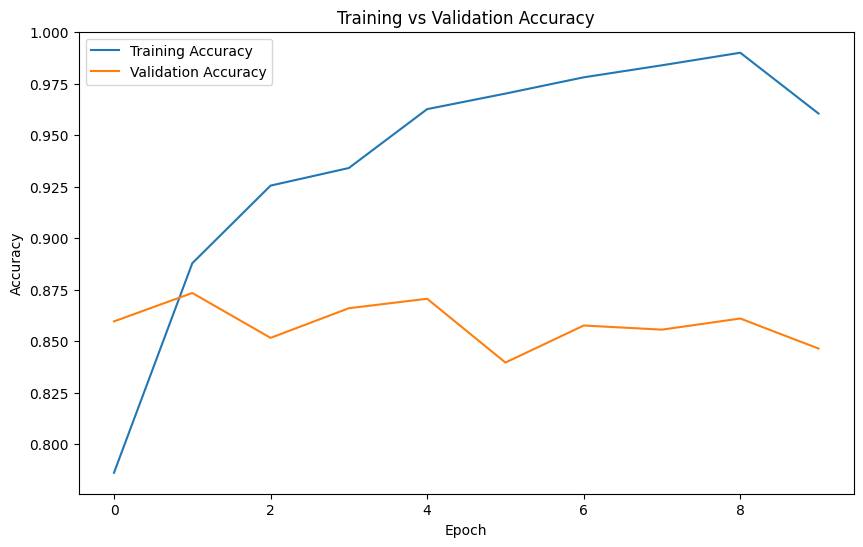

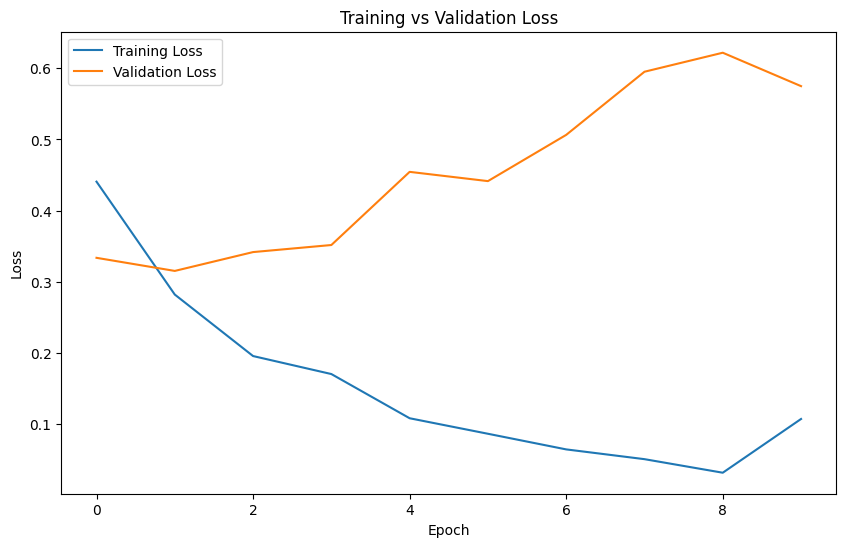

========== FINAL EPOCH RESULTS ==========
Training Accuracy:   0.9606
Validation Accuracy: 0.8464
Training Loss:       0.1068
Validation Loss:     0.5749
Training Time:       88.45 seconds


In [29]:

#TRAIN THE BASIC LSTM MODEL

import time
import matplotlib.pyplot as plt

#Compile the Model
model_lstm.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

#Training Settings
batch_size = 64
epochs = 10

print("Batch size:", batch_size)
print("Epochs:", epochs)

# Train the Model

start_time = time.time()

history_lstm = model_lstm.fit(
    X_train_final,
    y_train_final,

# Number of samples processed at one time
batch_size=batch_size,

# Number of complete passes through the training data
 epochs=epochs,

# Evaluate validation performance after each epoch
validation_data=(X_val, y_val),

# Show progress during training
 verbose=1
)

end_time = time.time()

training_time = end_time - start_time

print(f"\nTraining time: {training_time:.2f} seconds")

# Display Training History

print("\nTraining History:")
print(history_lstm.history.keys())

#Plot Training vs Validation Accuracy

plt.figure(figsize=(10, 6))

plt.plot(
    history_lstm.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_lstm.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Plot Training vs Validation Loss

plt.figure(figsize=(10, 6))

plt.plot(
    history_lstm.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_lstm.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

# CELL 7 — Print Final Epoch Results

final_train_accuracy = history_lstm.history["accuracy"][-1]
final_val_accuracy = history_lstm.history["val_accuracy"][-1]

final_train_loss = history_lstm.history["loss"][-1]
final_val_loss = history_lstm.history["val_loss"][-1]

print("========== FINAL EPOCH RESULTS ==========")

print(f"Training Accuracy:   {final_train_accuracy:.4f}")
print(f"Validation Accuracy: {final_val_accuracy:.4f}")

print(f"Training Loss:       {final_train_loss:.4f}")
print(f"Validation Loss:     {final_val_loss:.4f}")

print(f"Training Time:       {training_time:.2f} seconds")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 500, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,994,565 (15.24 MB)

 Trainable params: 1,331,521 (5.08 MB)

 Non-trainable params: 0 (0.00 B)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 500, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,382,977 (5.28 MB)

 Trainable params: 1,382,977 (5.28 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 18s 48ms/step - accuracy: 0.8043 - loss: 0.4092 - val_accuracy: 0.8650 - val_loss: 0.3353
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 15s 47ms/step - accuracy: 0.9099 - loss: 0.2277 - val_accuracy: 0.8460 - val_loss: 0.3417
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - accuracy: 0.9246 - loss: 0.1971 - val_accuracy: 0.8552 - val_loss: 0.3567
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 21s 44ms/step - accuracy: 0.9588 - loss: 0.1125 - val_accuracy: 0.8656 - val_loss: 0.4268
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 43ms/step - accuracy: 0.9744 - loss: 0.0721 - val_accuracy: 0.8542 - val_loss: 0.4421
Epoch 6/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 14s 43ms/step - accuracy: 0.9857 - loss: 0.0409 - val_accuracy: 0.8584 - val_loss: 0.6215
Epoch 7/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 15s 46ms/step - accuracy: 0.9859 - loss: 0.0414 - val_accuracy: 0.8542 - val_loss: 0.5692
Epoch 8/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 43ms/step - accuracy: 0.9898 - loss: 0.0296 - 

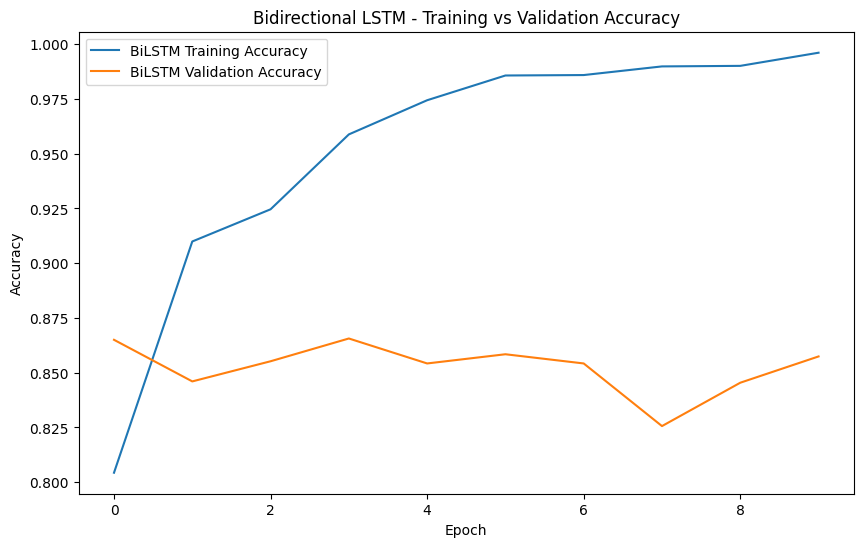

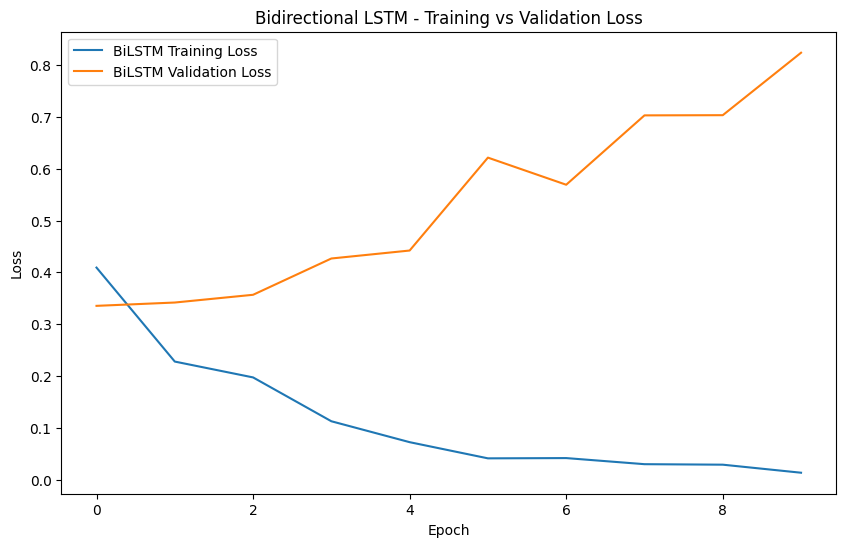

========== MODEL COMPARISON ==========


,Model,Training Accuracy,Validation Accuracy,Training Time (seconds),Parameters
0,Basic LSTM,0.96055,0.8464,88.449935,1331521
1,Bidirectional LSTM,0.99610,0.8574,148.560689,1382977


In [31]:

# PART 5 — MODEL IMPROVEMENT & COMPARISON

import time
import pandas as pd

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Bidirectional, Dense

# MODEL 1 — BASIC LSTM

model_lstm.summary()

# MODEL 2 — BIDIRECTIONAL LSTM

model_bilstm = Sequential([
    Input(shape=(maxlen,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        mask_zero=True
    ),

    Bidirectional(
        LSTM(lstm_units)
    ),

    Dense(dense_units, activation="relu"),

    Dense(1, activation="sigmoid")
])

model_bilstm.summary()

# COMPILE MODEL 2

model_bilstm.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# TRAIN MODEL 2

batch_size = 64
epochs = 10

start_time_bilstm = time.time()

history_bilstm = model_bilstm.fit(
    X_train_final,
    y_train_final,
    batch_size=batch_size,
    epochs=epochs,
    validation_data=(X_val, y_val),
    verbose=1
)

end_time_bilstm = time.time()

training_time_bilstm = end_time_bilstm - start_time_bilstm

print(f"BiLSTM Training Time: {training_time_bilstm:.2f} seconds")

# MODEL 2 ACCURACY GRAPH

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    history_bilstm.history["accuracy"],
    label="BiLSTM Training Accuracy"
)

plt.plot(
    history_bilstm.history["val_accuracy"],
    label="BiLSTM Validation Accuracy"
)

plt.title("Bidirectional LSTM - Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# MODEL 2 LOSS GRAPH

plt.figure(figsize=(10, 6))

plt.plot(
    history_bilstm.history["loss"],
    label="BiLSTM Training Loss"
)

plt.plot(
    history_bilstm.history["val_loss"],
    label="BiLSTM Validation Loss"
)

plt.title("Bidirectional LSTM - Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

# EXTRACT RESULTS

lstm_train_acc = history_lstm.history["accuracy"][-1]
lstm_val_acc = history_lstm.history["val_accuracy"][-1]

bilstm_train_acc = history_bilstm.history["accuracy"][-1]
bilstm_val_acc = history_bilstm.history["val_accuracy"][-1]

lstm_params = model_lstm.count_params()
bilstm_params = model_bilstm.count_params()

# MODEL COMPARISON

comparison_data = {
    "Model": [
        "Basic LSTM",
        "Bidirectional LSTM"
    ],
    "Training Accuracy": [
        lstm_train_acc,
        bilstm_train_acc
    ],
    "Validation Accuracy": [
        lstm_val_acc,
        bilstm_val_acc
    ],
    "Training Time (seconds)": [
        training_time,
        training_time_bilstm
    ],
    "Parameters": [
        lstm_params,
        bilstm_params
    ]
}

comparison_table = pd.DataFrame(comparison_data)

print("========== MODEL COMPARISON ==========")
display(comparison_table)

In [1]:
# COMPLETE MODEL COMPARISON

import os
import json
import pandas as pd

from google.colab import drive

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import load_model

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Mount Google Drive
drive.mount("/content/drive")

# Project folder
save_dir = "/content/drive/MyDrive/IMDB_Sentiment_Project"

# Project settings
vocab_size = 10000
maxlen = 500

# Load saved models from Google Drive
model_lstm = load_model(
    os.path.join(save_dir, "basic_lstm_model.keras")
)

model_bilstm = load_model(
    os.path.join(save_dir, "bilstm_model.keras")
)

print("Basic LSTM loaded successfully.")
print("BiLSTM loaded successfully.")

# Load IMDB dataset
(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

print("\nOriginal Training Data:", X_train.shape)
print("Original Test Data:", X_test.shape)

# Recreate the same validation split
X_train_raw, X_val_raw, y_train_final, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("\nTraining Samples:", len(X_train_raw))
print("Validation Samples:", len(X_val_raw))

# Apply same padding/truncation
X_train_final = pad_sequences(
    X_train_raw,
    maxlen=maxlen,
    padding="post",
    truncating="post"
)

X_val = pad_sequences(
    X_val_raw,
    maxlen=maxlen,
    padding="post",
    truncating="post"
)

print("\nTraining Shape:", X_train_final.shape)
print("Validation Shape:", X_val.shape)

# Generate predictions
print("\nGenerating Basic LSTM predictions...")

lstm_prob = model_lstm.predict(
    X_val,
    verbose=0
).ravel()

print("Generating BiLSTM predictions...")

bilstm_prob = model_bilstm.predict(
    X_val,
    verbose=0
).ravel()

lstm_pred = (lstm_prob >= 0.5).astype(int)
bilstm_pred = (bilstm_prob >= 0.5).astype(int)

# Calculate metrics for Basic LSTM
lstm_accuracy = accuracy_score(y_val, lstm_pred)
lstm_precision = precision_score(y_val, lstm_pred)
lstm_recall = recall_score(y_val, lstm_pred)
lstm_f1 = f1_score(y_val, lstm_pred)

# Calculate metrics for BiLSTM
bilstm_accuracy = accuracy_score(y_val, bilstm_pred)
bilstm_precision = precision_score(y_val, bilstm_pred)
bilstm_recall = recall_score(y_val, bilstm_pred)
bilstm_f1 = f1_score(y_val, bilstm_pred)

# Parameter counts
lstm_params = model_lstm.count_params()
bilstm_params = model_bilstm.count_params()

# Load saved results for training times
results_file = os.path.join(
    save_dir,
    "final_results.json"
)

training_time_lstm = None
training_time_bilstm = None

if os.path.exists(results_file):

    with open(results_file, "r") as f:
        saved_results = json.load(f)

    print("\nSaved results file found.")
    print("Available result keys:")
    print(list(saved_results.keys()))

    possible_lstm_keys = [
        "training_time_lstm",
        "lstm_training_time",
        "Basic LSTM Training Time",
        "basic_lstm_training_time"
    ]

    possible_bilstm_keys = [
        "training_time_bilstm",
        "bilstm_training_time",
        "BiLSTM Training Time",
        "bilstm_training_time"
    ]

    for key in possible_lstm_keys:
        if key in saved_results:
            training_time_lstm = saved_results[key]
            break

    for key in possible_bilstm_keys:
        if key in saved_results:
            training_time_bilstm = saved_results[key]
            break

if training_time_lstm is None:
    training_time_lstm = 88.45

if training_time_bilstm is None:
    training_time_bilstm = 156.05

# Create final comparison table
comparison_data = {
    "Model": [
        "Basic LSTM",
        "Bidirectional LSTM"
    ],
    "Accuracy (%)": [
        round(lstm_accuracy * 100, 2),
        round(bilstm_accuracy * 100, 2)
    ],
    "Precision (%)": [
        round(lstm_precision * 100, 2),
        round(bilstm_precision * 100, 2)
    ],
    "Recall (%)": [
        round(lstm_recall * 100, 2),
        round(bilstm_recall * 100, 2)
    ],
    "F1 Score (%)": [
        round(lstm_f1 * 100, 2),
        round(bilstm_f1 * 100, 2)
    ],
    "Training Time (sec)": [
        training_time_lstm,
        training_time_bilstm
    ],
    "Parameters": [
        lstm_params,
        bilstm_params
    ]
}

comparison_table = pd.DataFrame(comparison_data)

print("\nFINAL MODEL COMPARISON")

display(comparison_table)

Mounted at /content/drive
Basic LSTM loaded successfully.
BiLSTM loaded successfully.
17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Original Training Data: (25000,)
Original Test Data: (25000,)

Training Samples: 20000
Validation Samples: 5000

Training Shape: (20000, 500)
Validation Shape: (5000, 500)

Generating Basic LSTM predictions...
Generating BiLSTM predictions...

Saved results file found.
Available result keys:
['test_accuracy', 'test_precision', 'test_recall', 'test_f1_score', 'test_loss', 'best_validation_accuracy', 'best_validation_loss', 'regularized_training_time_seconds']

FINAL MODEL COMPARISON


,Model,Accuracy (%),Precision (%),Recall (%),F1 Score (%),Training Time (sec),Parameters
0,Basic LSTM,84.64,82.63,87.72,85.10,88.45,1331521
1,Bidirectional LSTM,85.74,84.19,88.00,86.06,156.05,1382977


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 500, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,331,521 (5.08 MB)

 Trainable params: 1,331,521 (5.08 MB)

 Non-trainable params: 0 (0.00 B)

Batch size: 64
Maximum epochs: 10
Dropout rate: 0.3
Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 12s 27ms/step - accuracy: 0.7466 - loss: 0.5103 - val_accuracy: 0.7308 - val_loss: 0.5273
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 27ms/step - accuracy: 0.8713 - loss: 0.3130 - val_accuracy: 0.8620 - val_loss: 0.3157
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.9172 - loss: 0.2172 - val_accuracy: 0.8702 - val_loss: 0.3131
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.9409 - loss: 0.1626 - val_accuracy: 0.8630 - val_loss: 0.3340
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 27ms/step - accuracy: 0.9589 - loss: 0.1140 - val_accuracy: 0.8714 - val_loss: 0.3638
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 3.

Regularized LSTM training time: 46.63 seconds
Epochs actually completed: 5
Best epoch: 3
Best validation loss: 0.3131
Best validation accuracy: 0.8714


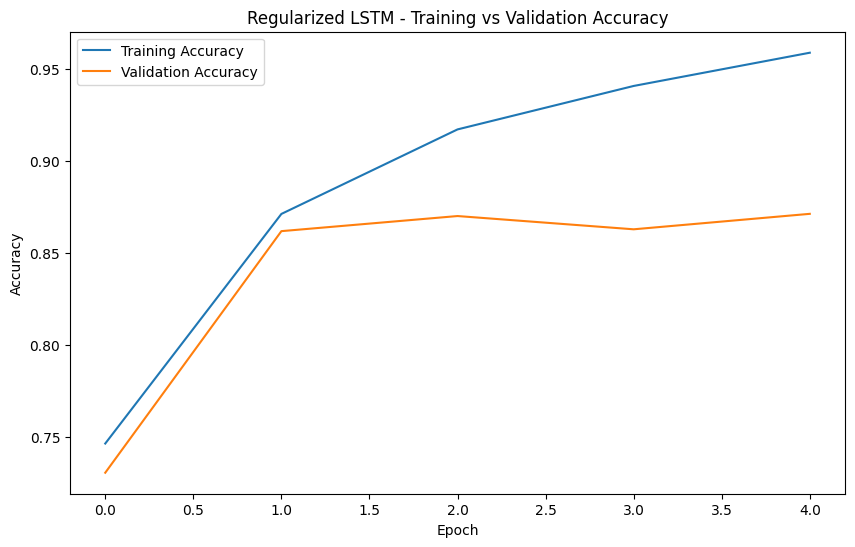

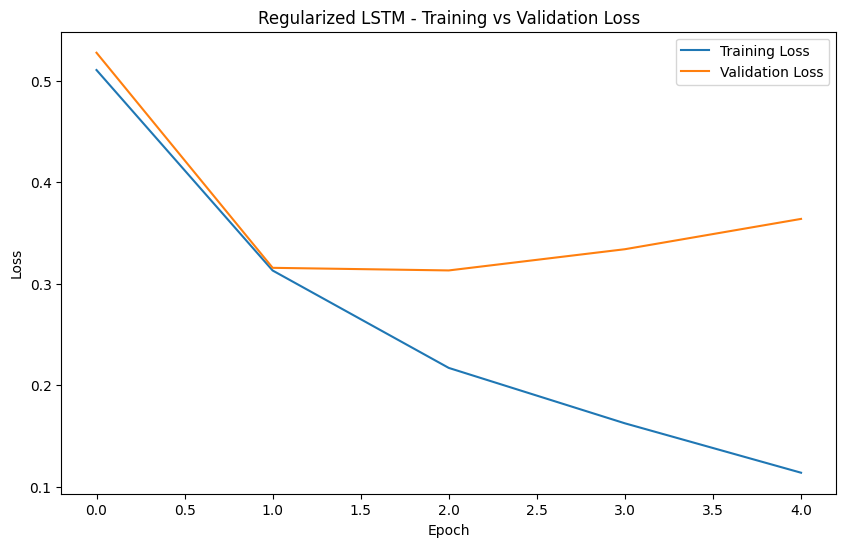


========== REGULARIZED LSTM RESULTS ==========
Training Accuracy:   0.9589
Validation Accuracy: 0.8714
Training Loss:       0.1140
Validation Loss:     0.3638
Training Time:       46.63 seconds


In [32]:

# PART 6 — REGULARIZATION

import time
import matplotlib.pyplot as plt
import numpy as np

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# 1. DEFINE REGULARIZATION SETTINGS

dropout_rate = 0.30

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
    verbose=1
)

# 2. BUILD REGULARIZED LSTM MODEL

model_lstm_regularized = Sequential([

    Input(shape=(maxlen,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        mask_zero=True
    ),

    LSTM(lstm_units),

    Dropout(dropout_rate),

    Dense(dense_units, activation="relu"),

    Dense(1, activation="sigmoid")
])

# 3. MODEL SUMMARY

model_lstm_regularized.summary()

# 4. COMPILE MODEL

model_lstm_regularized.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# 5. TRAINING SETTINGS

batch_size = 64
epochs = 10

print("Batch size:", batch_size)
print("Maximum epochs:", epochs)
print("Dropout rate:", dropout_rate)

# 6. TRAIN MODEL

start_time_regularized = time.time()

history_regularized = model_lstm_regularized.fit(
    X_train_final,
    y_train_final,
    batch_size=batch_size,
    epochs=epochs,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping],
    verbose=1
)

end_time_regularized = time.time()

training_time_regularized = (
    end_time_regularized - start_time_regularized
)

print(
    f"\nRegularized LSTM training time: "
    f"{training_time_regularized:.2f} seconds"
)

# 7. CHECK HOW MANY EPOCHS WERE ACTUALLY RUN

epochs_completed = len(history_regularized.history["loss"])

print("Epochs actually completed:", epochs_completed)

# 8. FIND BEST EPOCH

best_epoch = (
    np.argmin(history_regularized.history["val_loss"]) + 1
)

best_val_loss = min(history_regularized.history["val_loss"])

best_val_accuracy = max(
    history_regularized.history["val_accuracy"]
)

print("Best epoch:", best_epoch)
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Best validation accuracy: {best_val_accuracy:.4f}")

# 9. TRAINING VS VALIDATION ACCURACY

plt.figure(figsize=(10, 6))

plt.plot(
    history_regularized.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_regularized.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Regularized LSTM - Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

# 10. TRAINING VS VALIDATION LOSS

plt.figure(figsize=(10, 6))

plt.plot(
    history_regularized.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_regularized.history["val_loss"],
    label="Validation Loss"
)

plt.title("Regularized LSTM - Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

# 11. FINAL RESULTS

final_train_accuracy = history_regularized.history["accuracy"][-1]
final_val_accuracy = history_regularized.history["val_accuracy"][-1]

final_train_loss = history_regularized.history["loss"][-1]
final_val_loss = history_regularized.history["val_loss"][-1]

print("\n========== REGULARIZED LSTM RESULTS ==========")

print(f"Training Accuracy:   {final_train_accuracy:.4f}")
print(f"Validation Accuracy: {final_val_accuracy:.4f}")

print(f"Training Loss:       {final_train_loss:.4f}")
print(f"Validation Loss:     {final_val_loss:.4f}")

print(f"Training Time:       {training_time_regularized:.2f} seconds")

In [33]:
val_loss, val_accuracy = model_lstm_regularized.evaluate(
    X_val,
    y_val,
    verbose=0
)

print(f"Restored Best Model Validation Loss: {val_loss:.4f}")
print(f"Restored Best Model Validation Accuracy: {val_accuracy:.4f}")

Restored Best Model Validation Loss: 0.3131
Restored Best Model Validation Accuracy: 0.8702


782/782 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.8648 - loss: 0.3214

========== TEST SET RESULTS ==========
Test Loss:     0.3214
Test Accuracy: 0.8648
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step

========== FINAL TEST METRICS ==========
Accuracy:  0.8648
Precision: 0.8592
Recall:    0.8726
F1 Score:  0.8659

========== CONFUSION MATRIX ==========
[[10713  1787]
 [ 1592 10908]]


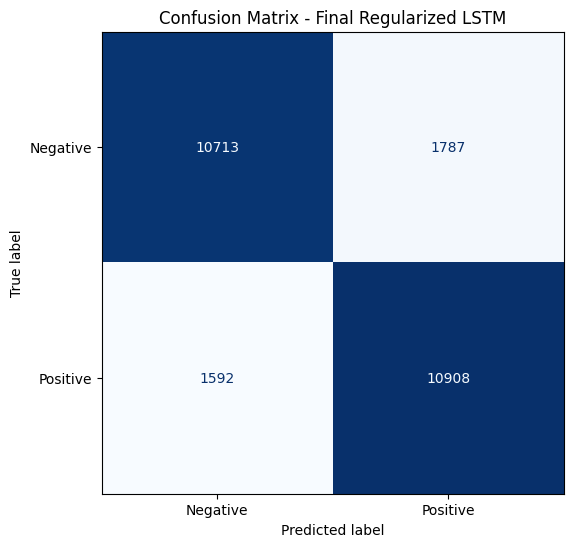


========== CONFUSION MATRIX COMPONENTS ==========
True Negative : 10713
False Positive: 1787
False Negative: 1592
True Positive : 10908

========== PREDICTION CHECK ==========
Test samples: 25000
Predictions : 25000
Probabilities: 25000

========== FINAL MODEL SUMMARY ==========
Test Accuracy : 0.8648
Test Precision: 0.8592
Test Recall   : 0.8726
Test F1 Score : 0.8659
Test Loss     : 0.3214


In [34]:

# PART 7 — FINAL MODEL EVALUATION

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Evaluate Final Model on Test Dataset

test_loss, test_accuracy = model_lstm_regularized.evaluate(
    X_test_padded,
    y_test,
    verbose=1
)

print("\n========== TEST SET RESULTS ==========")
print(f"Test Loss:     {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

# Generate Predictions

# Model returns probabilities between 0 and 1
y_pred_prob = model_lstm_regularized.predict(
    X_test_padded,
    verbose=1
)

# Convert (25000, 1) into (25000,)
y_pred_prob = y_pred_prob.ravel()

# Convert probabilities into class labels
# >= 0.5 → Positive (1)
# < 0.5  → Negative (0)
y_pred = (y_pred_prob >= 0.5).astype(int)

#Calculate Evaluation Metrics

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)


print("\n========== FINAL TEST METRICS ==========")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

# Confusion Matrix

cm = confusion_matrix(
    y_test,
    y_pred
)

print("\n========== CONFUSION MATRIX ==========")
print(cm)

# Display Confusion Matrix

display_labels = [
    "Negative",
    "Positive"
]

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_labels
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    ax=ax,
    values_format="d",
    cmap="Blues",
    colorbar=False
)

ax.set_title("Confusion Matrix - Final Regularized LSTM")
plt.show()

# Calculate Confusion Matrix Components

tn, fp, fn, tp = cm.ravel()

print("\n========== CONFUSION MATRIX COMPONENTS ==========")

print("True Negative :", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive :", tp)

# Verify Number of Predictions

print("\n========== PREDICTION CHECK ==========")
print("Test samples:", len(y_test))
print("Predictions :", len(y_pred))
print("Probabilities:", len(y_pred_prob))

# Final Evaluation Summary

print("\n========== FINAL MODEL SUMMARY ==========")

print(f"Test Accuracy : {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall   : {recall:.4f}")
print(f"Test F1 Score : {f1:.4f}")
print(f"Test Loss     : {test_loss:.4f}")

In [35]:

# SAVE ALL TRAINED MODELS AND SETTINGS TO GOOGLE DRIVE

from google.colab import drive
import json
import os

# Mount Google Drive
drive.mount('/content/drive')

# Create a folder for the project
save_dir = "/content/drive/MyDrive/IMDB_Sentiment_Project"
os.makedirs(save_dir, exist_ok=True)

# 1. SAVE BASIC LSTM

model_lstm.save(
    os.path.join(save_dir, "basic_lstm_model.keras")
)

# 2. SAVE BIDIRECTIONAL LSTM

model_bilstm.save(
    os.path.join(save_dir, "bilstm_model.keras")
)

# 3. SAVE FINAL REGULARIZED LSTM

# This is our final model for later prediction/evaluation.
model_lstm_regularized.save(
 os.path.join(save_dir, "final_regularized_lstm_model.keras")
)

# 4. SAVE IMPORTANT SETTINGS

config = {
    "vocab_size": int(vocab_size),
    "maxlen": int(maxlen),
    "embedding_dim": int(embedding_dim),
    "lstm_units": int(lstm_units),
    "dense_units": int(dense_units),
    "dropout_rate": float(dropout_rate)
}

with open(
    os.path.join(save_dir, "model_config.json"),
    "w"
) as f:
    json.dump(config, f, indent=4)

# SAVE IMDB WORD INDEX

with open(
    os.path.join(save_dir, "word_index.json"),
    "w"
) as f:
    json.dump(word_index, f)

# 6. SAVE FINAL TEST RESULTS

results = {
    "test_accuracy": float(accuracy),
    "test_precision": float(precision),
    "test_recall": float(recall),
    "test_f1_score": float(f1),
    "test_loss": float(test_loss),

    "best_validation_accuracy": float(val_accuracy),
    "best_validation_loss": float(val_loss),

    "regularized_training_time_seconds":
        float(training_time_regularized)
}

with open(
    os.path.join(save_dir, "final_results.json"),
    "w"
) as f:
    json.dump(results, f, indent=4)


# ------------------------------------------------------------
# 7. CONFIRM SAVED FILES
# ------------------------------------------------------------

print("==========================================")
print("ALL FILES SAVED SUCCESSFULLY")
print("==========================================")

for file_name in os.listdir(save_dir):
    print(file_name)

print("\nSaved location:")
print(save_dir)

Mounted at /content/drive
ALL FILES SAVED SUCCESSFULLY
basic_lstm_model.keras
bilstm_model.keras
final_regularized_lstm_model.keras
model_config.json
word_index.json
final_results.json

Saved location:
/content/drive/MyDrive/IMDB_Sentiment_Project


In [9]:

# PART 8 — REAL-WORLD PREDICTION

import os
import json
import numpy as np

from google.colab import drive
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.text import text_to_word_sequence
from tensorflow.keras.preprocessing.sequence import pad_sequences

# LOAD SAVED MODEL AND REQUIRED FILES

drive.mount("/content/drive")

save_dir = "/content/drive/MyDrive/IMDB_Sentiment_Project"

# Load final trained model
model_lstm_regularized = load_model(
    os.path.join(
        save_dir,
        "final_regularized_lstm_model.keras"
    )
)

# Load preprocessing configuration
with open(
    os.path.join(save_dir, "model_config.json"),
    "r"
) as f:
    config = json.load(f)

# Load IMDB word index
with open(
    os.path.join(save_dir, "word_index.json"),
    "r"
) as f:
    word_index = json.load(f)

# Restore preprocessing settings
vocab_size = config["vocab_size"]
maxlen = config["maxlen"]

print("Model loaded successfully.")
print("Vocabulary size:", vocab_size)
print("Maximum sequence length:", maxlen)

# 2. CONVERT RAW REVIEW INTO INTEGER IDs

def encode_review(review):

 # Convert raw text into words
words = text_to_word_sequence(review)

 encoded_review = []

 for word in words:
# Get original word index
index = word_index.get(word)

# Unknown or outside selected vocabulary
if index is None or index >= vocab_size - 3:
 encoded_review.append(2)  # <UNK>

else:
 # Shift index because of reserved IMDB tokens
encoded_review.append(index + 3)

    return encoded_review

#  PREDICT SENTIMENT

def predict_sentiment(review):

    # Convert raw review to integer sequence
    encoded_review = encode_review(review)

    # Pad/truncate to 500 tokens
    padded_review = pad_sequences(
        [encoded_review],
        maxlen=maxlen,
        padding="post",
        truncating="post"
    )

    # Get sigmoid probability
    probability = model_lstm_regularized.predict(
        padded_review,
        verbose=0
    )[0][0]

    # Convert probability into class
    if probability >= 0.5:
        sentiment = "Positive"
        confidence = probability
    else:
        sentiment = "Negative"
        confidence = 1 - probability

    return sentiment, confidence

#TEST ONE CUSTOM REVIEW

review = "This movie was absolutely fantastic. I really enjoyed it."

sentiment, confidence = predict_sentiment(review)

print("\n========== SINGLE REVIEW TEST ==========")
print("Review:", review)
print("Sentiment:", sentiment)
print(f"Confidence: {confidence * 100:.2f}%")

#  TEST 10 CUSTOM REVIEWS

custom_reviews = [

    # Clearly positive
    "This movie was absolutely amazing and I loved every minute of it.",

    # Clearly negative
    "This movie was terrible, boring, and a complete waste of time.",

    # Positive
    "Fantastic acting and an excellent story. I really enjoyed this film.",

    # Negative
    "I hated this movie. The story was weak and the acting was awful.",

    # Short positive
    "Amazing movie!",

    # Short negative
    "Very boring.",

    # Negation
    "I don't think this movie was good.",

    # Negation
    "This was not a bad movie. I actually enjoyed it.",

    # Mixed sentiment
    "The movie started well, but the ending was disappointing.",

    # Long review
    "The movie had beautiful visuals and some very good performances. "
    "The first half was engaging and the characters were interesting, "
    "but the middle became slow and some scenes felt unnecessary. "
    "Despite these problems, the ending was satisfying and I enjoyed "
    "the overall experience."
]


print("\n========== 10 CUSTOM REVIEWS ==========\n")

for i, review in enumerate(custom_reviews, start=1):

    sentiment, confidence = predict_sentiment(review)

    print(f"Review {i}:")
    print(review)
    print("Sentiment:", sentiment)
    print(f"Confidence: {confidence * 100:.2f}%")
    print("-" * 70)


# NEGATION ANALYSIS

negation_reviews = [

    "I don't think this movie was good.",
    "This movie was not good.",
    "This movie was not bad.",
    "I did not enjoy this movie.",
    "I did not hate this movie."
]


print("\n========== NEGATION ANALYSIS ==========\n")

for review in negation_reviews:

    sentiment, confidence = predict_sentiment(review)

    print("Review:", review)
    print("Prediction:", sentiment)
    print(f"Confidence: {confidence * 100:.2f}%")
    print("-" * 70)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model loaded successfully.
Vocabulary size: 10000
Maximum sequence length: 500

========== SINGLE REVIEW TEST ==========
Review: This movie was absolutely fantastic. I really enjoyed it.
Sentiment: Positive
Confidence: 73.61%

========== 10 CUSTOM REVIEWS ==========

Review 1:
This movie was absolutely amazing and I loved every minute of it.
Sentiment: Positive
Confidence: 88.17%
----------------------------------------------------------------------
Review 2:
This movie was terrible, boring, and a complete waste of time.
Sentiment: Negative
Confidence: 99.60%
----------------------------------------------------------------------
Review 3:
Fantastic acting and an excellent story. I really enjoyed this film.
Sentiment: Positive
Confidence: 93.43%
----------------------------------------------------------------------
Review 4:
I hated this movie. The story was w

In [10]:

# PART 9 — ERROR ANALYSIS
import os
import json
import numpy as np
import pandas as pd

from google.colab import drive
from tensorflow.keras.models import load_model
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

# LOAD GOOGLE DRIVE AND FINAL MODEL

drive.mount("/content/drive")

save_dir = "/content/drive/MyDrive/IMDB_Sentiment_Project"

model_lstm_regularized = load_model(
    os.path.join(
        save_dir,
        "final_regularized_lstm_model.keras"
    )
)

# LOAD MODEL CONFIGURATION

with open(
    os.path.join(save_dir, "model_config.json"),
    "r"
) as f:
    config = json.load(f)

vocab_size = config["vocab_size"]
maxlen = config["maxlen"]

print("Model loaded successfully.")
print("Vocabulary size:", vocab_size)
print("Maximum sequence length:", maxlen)

# 3. LOAD IMDB TEST DATA

(_, _), (X_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

# Pad/truncate test reviews exactly as in training
X_test_padded = pad_sequences(
    X_test,
    maxlen=maxlen,
    padding="post",
    truncating="post"
)

print("\nTest data shape:", X_test_padded.shape)
print("Test labels shape:", y_test.shape)

# GENERATE PREDICTIONS

y_pred_prob = model_lstm_regularized.predict(
    X_test_padded,
    verbose=1
).ravel()

# Convert probability to class
y_pred = (y_pred_prob >= 0.5).astype(int)

#FIND INCORRECT PREDICTIONS

incorrect_indices = np.where(
    y_pred != y_test
)[0]

print("\n========== ERROR SUMMARY ==========")
print("Total test reviews:", len(y_test))
print("Incorrect predictions:", len(incorrect_indices))

error_rate = (
    len(incorrect_indices) / len(y_test)
) * 100

print(f"Error rate: {error_rate:.2f}%")

# LOAD WORD INDEX

with open(
    os.path.join(save_dir, "word_index.json"),
    "r"
) as f:
    word_index = json.load(f)

# CREATE REVERSE WORD INDEX

reverse_word_index = {
    int(value) + 3: key
    for key, value in word_index.items()
}

reverse_word_index[0] = "<PAD>"
reverse_word_index[1] = "<START>"
reverse_word_index[2] = "<UNK>"
reverse_word_index[3] = "<UNUSED>"

# FUNCTION TO DECODE REVIEW

def decode_review(encoded_review):

    words = []

    for token_id in encoded_review:

        # Stop displaying after padding starts
        if token_id == 0:
            break

        words.append(
            reverse_word_index.get(
                int(token_id),
                "?"
            )
        )

    return " ".join(words)


# CREATE ERROR DATAFRAME

error_records = []

for idx in incorrect_indices:

actual = int(y_test[idx])
predicted = int(y_pred[idx])

 # Confidence of the predicted class
if predicted == 1:
  confidence = y_pred_prob[idx]
    else:
        confidence = 1 - y_pred_prob[idx]

 error_records.append({

  "Index": int(idx),

        "Actual": (
            "Positive"
            if actual == 1
            else "Negative"
        ),

        "Predicted": (
            "Positive"
            if predicted == 1
            else "Negative"
        ),

        "Confidence": float(confidence),

        "Review Length": len(X_test[idx]),

        "Review": decode_review(X_test[idx])
    })


errors_df = pd.DataFrame(error_records)

# DISPLAY 10 INCORRECT REVIEWS

print("\n========== 10 INCORRECTLY CLASSIFIED REVIEWS ==========\n")

for i in range(min(10, len(errors_df))):

    row = errors_df.iloc[i]

    print(f"Error {i + 1}")
    print("Actual Sentiment:", row["Actual"])
    print("Predicted Sentiment:", row["Predicted"])
    print(
        f"Confidence: {row['Confidence'] * 100:.2f}%"
    )
    print("Review Length:", row["Review Length"])
    print("Review:")
    print(row["Review"])
    print("-" * 80)

#SHORTEST INCORRECT REVIEWS

print("\n========== SHORTEST INCORRECT REVIEWS ==========\n")

short_errors = errors_df.sort_values(
    by="Review Length"
).head(5)

display(
    short_errors[
        [
            "Actual",
            "Predicted",
            "Confidence",
            "Review Length",
            "Review"
        ]
    ]
)

# LONGEST INCORRECT REVIEWS

print("\n========== LONGEST INCORRECT REVIEWS ==========\n")

long_errors = errors_df.sort_values(
    by="Review Length",
    ascending=False
).head(5)

display(
    long_errors[
        [
            "Actual",
            "Predicted",
            "Confidence",
            "Review Length",
            "Review"
        ]
    ]
)

# LOW-CONFIDENCE ERRORS

print("\n========== LOW-CONFIDENCE ERRORS ==========\n")

low_confidence_errors = errors_df.sort_values(
    by="Confidence"
).head(5)

display(
    low_confidence_errors[
        [
            "Actual",
            "Predicted",
            "Confidence",
            "Review Length",
            "Review"
        ]
    ]
)

# NEGATION-RELATED ERRORS

negation_words = [
    "not",
    "no",
    "never",
    "nothing",
    "don't",
    "didn't",
    "isn't",
    "wasn't",
    "couldn't",
    "wouldn't",
    "shouldn't",
    "neither"
]

negation_pattern = (
    r"\b("
    + "|".join(negation_words)
    + r")\b"
)

negation_errors = errors_df[
    errors_df["Review"]
    .str.lower()
    .str.contains(
        negation_pattern,
        regex=True,
        na=False
    )
]

print("\n========== NEGATION-RELATED ERRORS ==========\n")

print(
    "Errors containing negation words:",
    len(negation_errors)
)

display(
    negation_errors[
        [
            "Actual",
            "Predicted",
            "Confidence",
            "Review Length",
            "Review"
        ]
    ].head(10)
)

#  SAVE ERROR ANALYSIS TO CSV

error_file = os.path.join(
    save_dir,
    "error_analysis.csv"
)

errors_df.to_csv(
    error_file,
    index=False
)

print("\nError analysis saved to:")
print(error_file)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model loaded successfully.
Vocabulary size: 10000
Maximum sequence length: 500
17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step

Test data shape: (25000, 500)
Test labels shape: (25000,)
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step

========== ERROR SUMMARY ==========
Total test reviews: 25000
Incorrect predictions: 3379
Error rate: 13.52%

========== 10 INCORRECTLY CLASSIFIED REVIEWS ==========

Error 1
Actual Sentiment: Positive
Predicted Sentiment: Negative
Confidence: 70.56%
Review Length: 603
Review:
<START> many animation buffs consider <UNK> <UNK> the great forgotten genius of one special branch of the art puppet animation which he invented almost single <UNK> and as it happened almost accidentally as a young man <UNK> was more interested in <UNK> than the cinema but his <UNK> attempt to film two <UNK> <UNK> fighting led to an unexpected breakthrough in

,Actual,Predicted,Confidence,Review Length,Review
25,Negative,Positive,0.607991,9,<START> more suspenseful more subtle much much...
2811,Negative,Positive,0.685187,24,<START> widow hires a psychopath as a <UNK> sl...
2749,Positive,Negative,0.654821,24,<START> very intelligent language usage of ali...
505,Positive,Negative,0.840844,29,<START> <UNK> boy's own paper nonsense with a ...
868,Positive,Negative,0.583557,29,<START> a really realistic sensible movie by <...



========== LONGEST INCORRECT REVIEWS ==========



,Actual,Predicted,Confidence,Review Length,Review
1429,Positive,Negative,0.895190,2119,<START> some spoilers included br br although ...
1365,Positive,Negative,0.712373,1700,<START> if anyone ever <UNK> a <UNK> on modern...
738,Positive,Negative,0.866252,1162,<START> the <UNK> of <UNK> 8 10 br br this rev...
1848,Positive,Negative,0.925557,1158,<START> 'the <UNK> of is one of shakespeare's ...
47,Positive,Negative,0.941510,1052,<START> <UNK> 6 is an entertaining <UNK> if no...



========== LOW-CONFIDENCE ERRORS ==========



,Actual,Predicted,Confidence,Review Length,Review
46,Positive,Negative,0.500932,108,<START> i bought this in the budget department...
3043,Positive,Negative,0.501033,191,<START> <UNK> is a hit and miss film set in th...
2857,Positive,Negative,0.501103,549,<START> okay sure this movie is a bit on the h...
2606,Negative,Positive,0.501422,140,<START> hope <UNK> with sandra <UNK> is a real...
531,Negative,Positive,0.501585,207,<START> i truly hate and despise this film and...



========== NEGATION-RELATED ERRORS ==========

Errors containing negation words: 2920


/tmp/ipykernel_9604/3679461324.py:316: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  .str.contains(


,Actual,Predicted,Confidence,Review Length,Review
0,Positive,Negative,0.705600,603,<START> many animation buffs consider <UNK> <U...
1,Negative,Positive,0.539211,181,<START> i generally love this type of movie ho...
3,Positive,Negative,0.722247,133,<START> if you expect that this movie is full ...
4,Positive,Negative,0.860804,256,<START> this is a special film if you know the...
5,Positive,Negative,0.685820,101,<START> alice is the kind of movie they made i...
6,Negative,Positive,0.959381,324,<START> the adventures of <UNK> has to be one ...
7,Positive,Negative,0.843354,157,<START> with the obvious exception of fools ho...
8,Positive,Negative,0.915627,135,<START> a quick glance at the premise of this ...
9,Positive,Negative,0.942536,173,<START> <UNK> is the first of its kind in turk...
10,Negative,Positive,0.759592,147,<START> if you want to see a horror film which...



Error analysis saved to:
/content/drive/MyDrive/IMDB_Sentiment_Project/error_analysis.csv


In [2]:
# PART 10 — BIDIRECTIONAL SEQUENCE MODELING

import os
import numpy as np

from google.colab import drive
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import load_model

# Mount Google Drive
drive.mount("/content/drive")

# Project settings
save_dir = "/content/drive/MyDrive/IMDB_Sentiment_Project"
vocab_size = 10000
maxlen = 500

# Load trained BiLSTM model
model_bilstm = load_model(
    os.path.join(save_dir, "bilstm_model.keras")
)

print("BiLSTM model loaded successfully.\n")

# Display model architecture
model_bilstm.summary()

# Load IMDB dataset
(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

# Pad sequences
X_train_padded = pad_sequences(
    X_train,
    maxlen=maxlen,
    padding="post",
    truncating="post"
)

# Select one sample
sample_input = X_train_padded[:1]

print("\nInput shape:", sample_input.shape)

# Embedding output
embedding_output = model_bilstm.layers[0](sample_input)

print("Embedding output shape:", embedding_output.shape)

# BiLSTM output
bilstm_output = model_bilstm.layers[1](embedding_output)

print("BiLSTM output shape:", bilstm_output.shape)

# Final prediction
prediction = model_bilstm.predict(
    sample_input,
    verbose=0
)[0][0]

print("Prediction probability:", prediction)

if prediction >= 0.5:
    print("Predicted sentiment: Positive")
else:
    print("Predicted sentiment: Negative")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
BiLSTM model loaded successfully.



Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 500, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,148,933 (15.83 MB)

 Trainable params: 1,382,977 (5.28 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,765,956 (10.55 MB)


Input shape: (1, 500)
Embedding output shape: (1, 500, 128)
BiLSTM output shape: (1, 128)
Prediction probability: 0.9999988
Predicted sentiment: Positive
